In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import seaborn as sns
from scipy import stats

In [3]:
df = pd.read_csv("../amz_uk_price_prediction_dataset.csv")

In [4]:
amazon = df.copy()

amazon["category"] = amazon["category"].astype(str).str.strip()

if amazon["isBestSeller"].dtype == "object":
    amazon["isBestSeller"] = amazon["isBestSeller"].astype(str).str.strip().str.lower().map({"true": True, "false": False, "1": True, "0": False})

amazon = amazon.dropna(subset=["category", "isBestSeller"])

# Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

## 1. Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [5]:
category_bestseller_crosstab = pd.crosstab(
    amazon["category"],
    amazon["isBestSeller"]
)

category_bestseller_crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [6]:
category_bestseller_crosstab = category_bestseller_crosstab.rename(columns={False: "not_best_seller", True: "best_seller"})

category_bestseller_crosstab.head()

isBestSeller,not_best_seller,best_seller
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [7]:
bestseller_summary = category_bestseller_crosstab.copy()

bestseller_summary["total_products"] = bestseller_summary.sum(axis=1)
bestseller_summary["bestseller_rate"] = bestseller_summary["best_seller"] / bestseller_summary["total_products"]

bestseller_summary = bestseller_summary.sort_values("bestseller_rate", ascending=False)

bestseller_summary.head(10)

isBestSeller,not_best_seller,best_seller,total_products,bestseller_rate
category,,,,
Grocery,9008,556,9564,0.058135
Smart Home Security & Lighting,98,6,104,0.057692
Health & Personal Care,9017,552,9569,0.057686
Mobile Phone Accessories,248,11,259,0.042471
Power & Hand Tools,8353,306,8659,0.035339
"Billiard, Snooker & Pool",241,8,249,0.032129
Pet Supplies,9152,285,9437,0.030200
Home Brewing & Wine Making,239,7,246,0.028455
Mirrors,243,7,250,0.028000


In [8]:
min_products = 100

bestseller_summary_filtered = bestseller_summary[bestseller_summary["total_products"] >= min_products]

bestseller_summary_filtered.head(10)

isBestSeller,not_best_seller,best_seller,total_products,bestseller_rate
category,,,,
Grocery,9008,556,9564,0.058135
Smart Home Security & Lighting,98,6,104,0.057692
Health & Personal Care,9017,552,9569,0.057686
Mobile Phone Accessories,248,11,259,0.042471
Power & Hand Tools,8353,306,8659,0.035339
"Billiard, Snooker & Pool",241,8,249,0.032129
Pet Supplies,9152,285,9437,0.030200
Home Brewing & Wine Making,239,7,246,0.028455
Mirrors,243,7,250,0.028000


In [12]:
bestseller_summary_filtered_display = bestseller_summary_filtered.copy()
bestseller_summary_filtered_display["bestseller_rate"] = (bestseller_summary_filtered_display["bestseller_rate"] * 100).round(2)

bestseller_summary_filtered_display[["total_products", "best_seller", "not_best_seller", "bestseller_rate"]].head(10)

isBestSeller,total_products,best_seller,not_best_seller,bestseller_rate
category,,,,
Grocery,9564,556,9008,5.81
Smart Home Security & Lighting,104,6,98,5.77
Health & Personal Care,9569,552,9017,5.77
Mobile Phone Accessories,259,11,248,4.25
Power & Hand Tools,8659,306,8353,3.53
"Billiard, Snooker & Pool",249,8,241,3.21
Pet Supplies,9437,285,9152,3.02
Home Brewing & Wine Making,246,7,239,2.85
Mirrors,250,7,243,2.80


## 2. Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

H0: Best-seller status is independent of product category.

H1: Best-seller status is not independent of product category.

In [13]:
chi2, p_value, dof, expected = chi2_contingency(category_bestseller_crosstab)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"p-value: {p_value:.10f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 36540.2027
p-value: 0.0000000000
Degrees of freedom: 295


In [14]:
def cramers_v(contingency_table):
    chi2, _, _, _ = chi2_contingency(contingency_table)
    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape
    return np.sqrt((chi2 / n) / min(rows - 1, cols - 1))

cramers_v_value = cramers_v(category_bestseller_crosstab)

print(f"Cramér's V: {cramers_v_value:.4f}")

Cramér's V: 0.1223


The Chi-square test shows a p-value below 0.05, so we reject the null hypothesis that product category and best-seller status are independent.

This means that there is statistical evidence of an association between product category and best-seller status. In other words, the proportion of best-seller products is not exactly the same across all product categories.

However, the p-value is extremely small mainly because the dataset is very large. With a large number of observations, even small differences between categories can become statistically significant.

For this reason, Cramér's V is more useful for interpreting the practical strength of the relationship. In this case, Cramér's V is 0.1223, which indicates a weak association between product category and best-seller status.

Therefore, while best-seller status does vary by category, the strength of this relationship is relatively weak. Product category has some influence on whether a product becomes a best-seller, but it is not a strong determining factor on its own.

## 3. Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

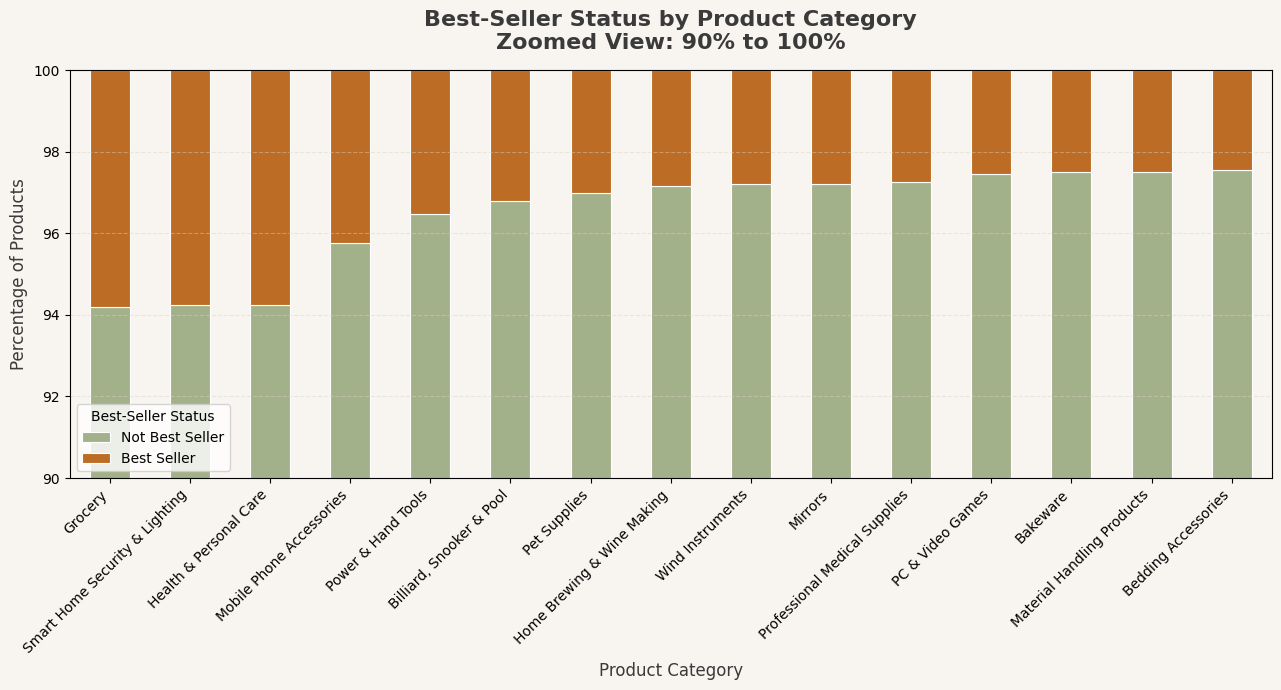

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

min_products = 100
top_n = 15

amazon = df.copy()
amazon["category"] = amazon["category"].astype(str).str.strip()

# Crosstab
category_bestseller_crosstab = pd.crosstab(amazon["category"], amazon["isBestSeller"])

# Ensure both columns exist
for col in [False, True]:
    if col not in category_bestseller_crosstab.columns:
        category_bestseller_crosstab[col] = 0

# Summary table
summary = category_bestseller_crosstab.copy()
summary["total_products"] = summary[False] + summary[True]
summary["bestseller_rate"] = summary[True] / summary["total_products"] * 100

# Filter and select top categories
top_categories = (
    summary[summary["total_products"] >= min_products]
    .sort_values("bestseller_rate", ascending=False)
    .head(top_n)
    .index
)

# Create stacked percentage data
stacked_data = pd.crosstab(
    amazon[amazon["category"].isin(top_categories)]["category"],
    amazon[amazon["category"].isin(top_categories)]["isBestSeller"],
    normalize="index"
) * 100

stacked_data = stacked_data.reindex(top_categories)
stacked_data = stacked_data.rename(columns={False: "Not Best Seller", True: "Best Seller"})

# Earth/nature palette
earth_palette = {
    "not_best": "#A3B18A",
    "best": "#BC6C25",
    "bg": "#F8F5F0",
    "grid": "#D9D2C3",
    "text": "#3A3A3A"
}

# Plot
ax = stacked_data.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    color=[earth_palette["not_best"], earth_palette["best"]],
    edgecolor="white",
    linewidth=0.8
)

fig = plt.gcf()
fig.patch.set_facecolor(earth_palette["bg"])
ax.set_facecolor(earth_palette["bg"])

plt.ylim(90, 100)
plt.title("Best-Seller Status by Product Category\nZoomed View: 90% to 100%", fontsize=16, weight="bold", pad=15, color=earth_palette["text"])
plt.xlabel("Product Category", fontsize=12, color=earth_palette["text"])
plt.ylabel("Percentage of Products", fontsize=12, color=earth_palette["text"])
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.45, color=earth_palette["grid"])
plt.legend(title="Best-Seller Status", loc="lower left", frameon=True)

plt.tight_layout()
plt.show()

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

## 0. Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.



In [27]:
amazon = df.copy()

amazon["category"] = amazon["category"].astype(str).str.strip()
amazon["price"] = pd.to_numeric(amazon["price"], errors="coerce")
amazon["stars"] = pd.to_numeric(amazon["stars"], errors="coerce")

amazon = amazon.dropna(subset=["category", "price"])
amazon = amazon[amazon["price"] > 0]

In [28]:
Q1 = amazon["price"].quantile(0.25)
Q3 = amazon["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

amazon_no_outliers = amazon[
    (amazon["price"] >= lower_bound) &
    (amazon["price"] <= upper_bound)
].copy()

print(f"Original rows: {amazon.shape[0]:,}")
print(f"Rows after removing price outliers: {amazon_no_outliers.shape[0]:,}")
print(f"Rows removed: {amazon.shape[0] - amazon_no_outliers.shape[0]:,}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")

Original rows: 2,443,631
Rows after removing price outliers: 2,115,943
Rows removed: 327,688
Lower bound: -44.01
Upper bound: 99.99


## 1. Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.


In [29]:
top_20_categories = (
    amazon_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

violin_data = amazon_no_outliers[
    amazon_no_outliers["category"].isin(top_20_categories)
].copy()

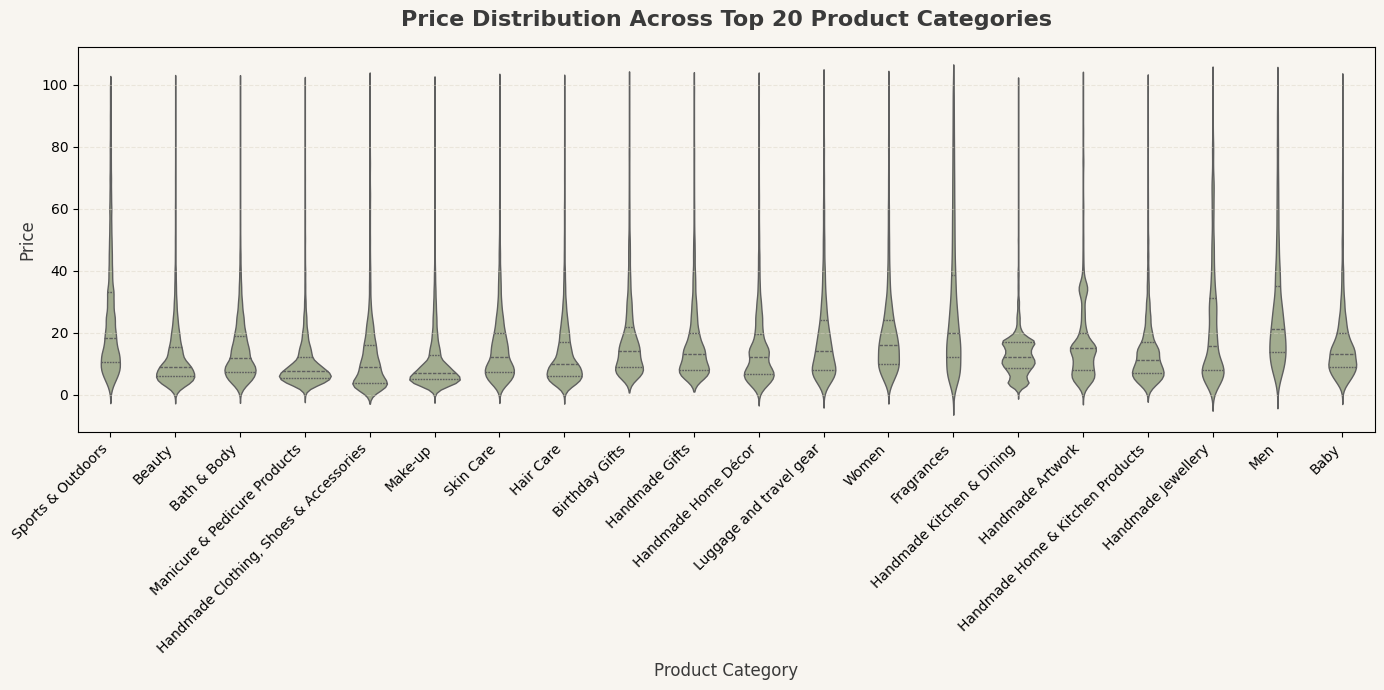

In [30]:
earth_palette = {
    "olive": "#7A8B5A",
    "sage": "#A3B18A",
    "terracotta": "#BC6C25",
    "sand": "#DDBEA9",
    "cream": "#F8F5F0",
    "grid": "#D9D2C3",
    "text": "#3A3A3A"
}

plt.figure(figsize=(14, 7), facecolor=earth_palette["cream"])
ax = sns.violinplot(
    data=violin_data,
    x="category",
    y="price",
    order=top_20_categories,
    color=earth_palette["sage"],
    inner="quartile",
    linewidth=1
)

ax.set_facecolor(earth_palette["cream"])

plt.title("Price Distribution Across Top 20 Product Categories", fontsize=16, weight="bold", pad=15, color=earth_palette["text"])
plt.xlabel("Product Category", fontsize=12, color=earth_palette["text"])
plt.ylabel("Price", fontsize=12, color=earth_palette["text"])
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.45, color=earth_palette["grid"])
plt.tight_layout()
plt.show()

In [33]:
median_price_by_category = (
    amazon_no_outliers
    .groupby("category")
    .agg(
        median_price=("price", "median"),
        product_count=("price", "count")
    )
    .sort_values("median_price", ascending=False)
)

median_price_by_category.head(10)

,median_price,product_count
category,,
Desktop PCs,74.00,169
Boxing Shoes,69.79,3873
Tablets,69.00,4638
Graphics Cards,68.54,57
Motherboards,67.92,74
Made in Italy Handmade,64.00,1561
Digital Frames,63.90,310
Streaming Clients,62.68,1692
Golf Shoes,62.39,4493


In [34]:
highest_median_price_category = median_price_by_category.head(1)

highest_median_price_category

,median_price,product_count
category,,
Desktop PCs,74.0,169


## 2. Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.


In [35]:
top_10_categories = (
    amazon_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

avg_price_top_10 = (
    amazon_no_outliers[amazon_no_outliers["category"].isin(top_10_categories)]
    .groupby("category")
    .agg(
        average_price=("price", "mean"),
        product_count=("price", "count")
    )
    .reindex(top_10_categories)
    .sort_values("average_price", ascending=False)
)

avg_price_top_10

,average_price,product_count
category,,
Sports & Outdoors,25.172246,694087
Birthday Gifts,18.600195,18398
Handmade Gifts,17.395112,17948
Skin Care,15.654722,18686
Bath & Body,14.678683,19050
Hair Care,13.461408,18625
"Handmade Clothing, Shoes & Accessories",12.958639,18811
Beauty,12.523480,19233
Make-up,10.612918,18718


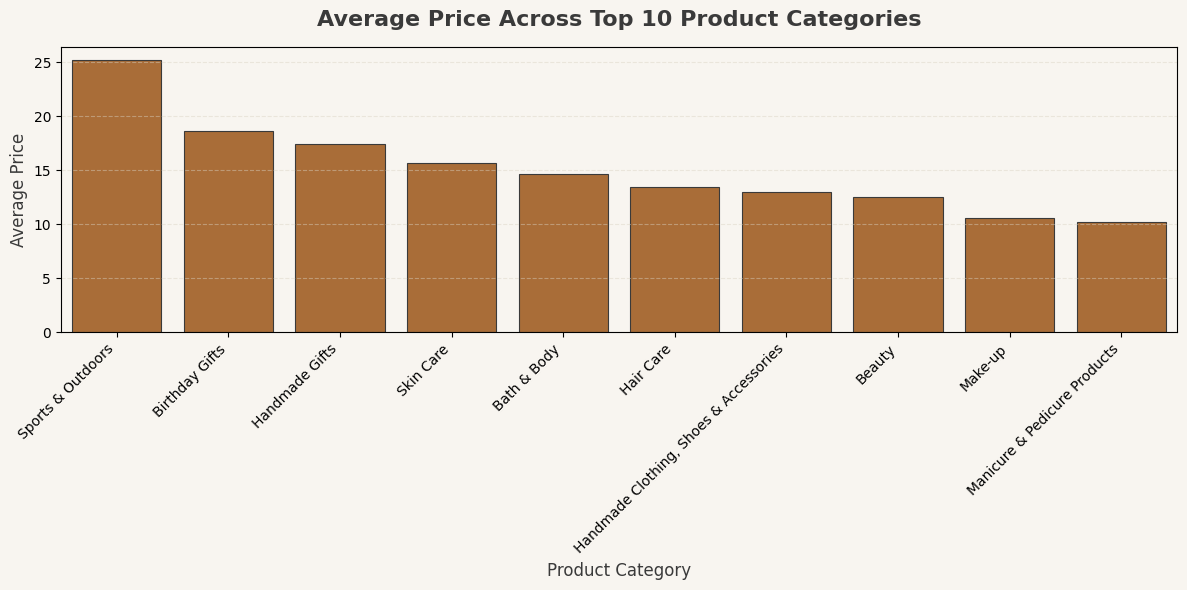

In [36]:
plt.figure(figsize=(12, 6), facecolor=earth_palette["cream"])
ax = sns.barplot(
    data=avg_price_top_10.reset_index(),
    x="category",
    y="average_price",
    color=earth_palette["terracotta"],
    edgecolor=earth_palette["text"],
    linewidth=0.8
)

ax.set_facecolor(earth_palette["cream"])

plt.title("Average Price Across Top 10 Product Categories", fontsize=16, weight="bold", pad=15, color=earth_palette["text"])
plt.xlabel("Product Category", fontsize=12, color=earth_palette["text"])
plt.ylabel("Average Price", fontsize=12, color=earth_palette["text"])
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.45, color=earth_palette["grid"])
plt.tight_layout()
plt.show()

In [37]:
avg_price_by_category = (
    amazon_no_outliers
    .groupby("category")
    .agg(
        average_price=("price", "mean"),
        product_count=("price", "count")
    )
    .sort_values("average_price", ascending=False)
)

avg_price_by_category.head(10)

,average_price,product_count
category,,
Motherboards,68.772432,74
Boxing Shoes,67.417803,3873
Desktop PCs,66.915562,169
Tablets,66.552971,4638
Graphics Cards,65.103509,57
Digital Frames,60.745129,310
Streaming Clients,60.241803,1692
Hockey Shoes,60.094796,221
Computer Cases,58.339884,173


In [38]:
highest_avg_price_category = avg_price_by_category.head(1)

highest_avg_price_category

,average_price,product_count
category,,
Motherboards,68.772432,74


## 3. Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [39]:
ratings_data = amazon_no_outliers.dropna(subset=["stars"]).copy()
ratings_data = ratings_data[ratings_data["stars"] > 0]

In [40]:
top_10_rating_categories = (
    ratings_data["category"]
    .value_counts()
    .head(10)
    .index
)

boxplot_data = ratings_data[
    ratings_data["category"].isin(top_10_rating_categories)
].copy()

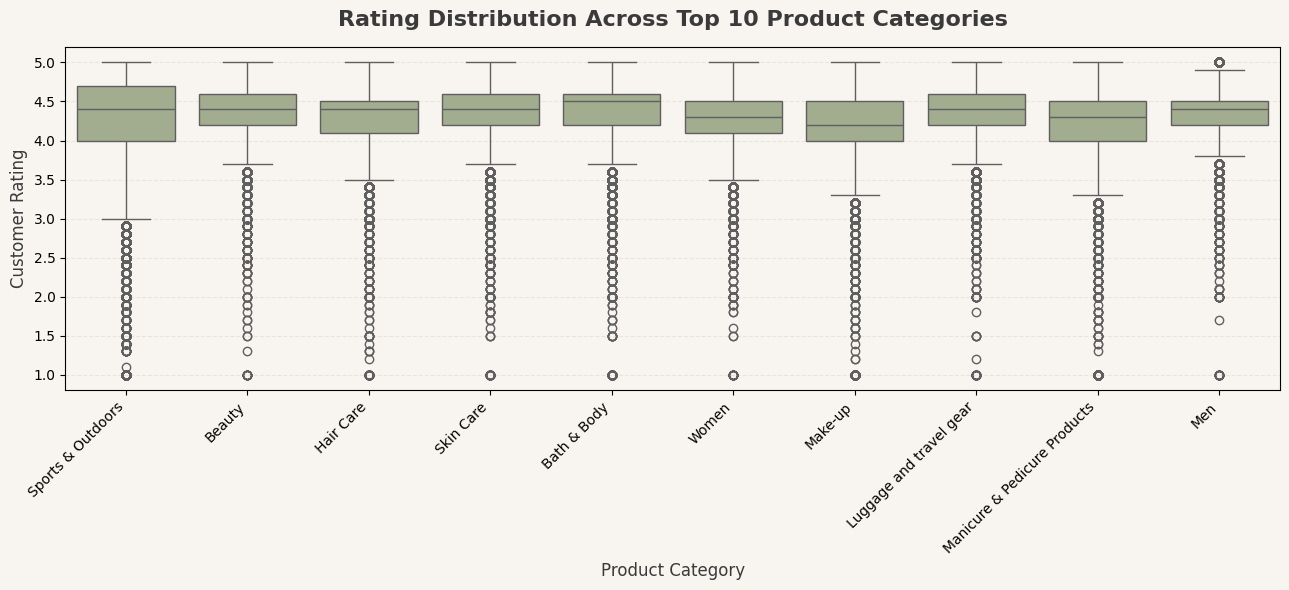

In [41]:
plt.figure(figsize=(13, 6), facecolor=earth_palette["cream"])
ax = sns.boxplot(
    data=boxplot_data,
    x="category",
    y="stars",
    order=top_10_rating_categories,
    color=earth_palette["sage"],
    linewidth=1
)

ax.set_facecolor(earth_palette["cream"])

plt.title("Rating Distribution Across Top 10 Product Categories", fontsize=16, weight="bold", pad=15, color=earth_palette["text"])
plt.xlabel("Product Category", fontsize=12, color=earth_palette["text"])
plt.ylabel("Customer Rating", fontsize=12, color=earth_palette["text"])
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.45, color=earth_palette["grid"])
plt.tight_layout()
plt.show()

Although the price outliers were removed before this analysis, the boxplot still shows outliers in customer ratings. These outliers represent products with unusually low ratings compared to the rest of their category. Since ratings are bounded between 1 and 5 and low ratings may represent genuine customer feedback, they were not removed from the analysis.

In [42]:
median_rating_by_category = (
    ratings_data
    .groupby("category")
    .agg(
        median_rating=("stars", "median"),
        product_count=("stars", "count")
    )
    .sort_values("median_rating", ascending=False)
)

median_rating_by_category.head(10)

,median_rating,product_count
category,,
Handmade Artwork,5.0,4155
Made in Italy Handmade,5.0,303
Handmade Baby Products,5.0,1235
"Handmade Clothing, Shoes & Accessories",4.9,4429
Handmade Kitchen & Dining,4.9,2739
Birthday Gifts,4.8,7875
Handmade Home Décor,4.8,7966
Handmade Gifts,4.8,9871
Handmade Home & Kitchen Products,4.7,10722


In [43]:
highest_median_rating_category = median_rating_by_category.head(1)

highest_median_rating_category

,median_rating,product_count
category,,
Handmade Artwork,5.0,4155


### Part 2 Summary

After removing price outliers using the IQR method, product prices were compared across categories.

The violin plot shows that price distributions vary noticeably between product categories. Some categories have wider price ranges, while others are concentrated around lower price points.

The median price analysis identifies which category tends to have the highest typical price, while the average price analysis highlights which category commands the highest mean price. These two metrics can differ because the mean is more sensitive to expensive products, even after removing outliers.

For customer ratings, products with 0 stars were excluded because they likely represent missing or unavailable ratings. The box plot shows how ratings vary across the top categories by product count, while the median rating table identifies the category with the highest typical customer rating across all categories.

Overall, product category appears to influence both price distribution and customer rating patterns, although price differences are generally easier to observe than rating differences.

# Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

## 1. Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

In [44]:
from scipy.stats import pearsonr, spearmanr

corr_data = amazon_no_outliers.copy()

corr_data["price"] = pd.to_numeric(corr_data["price"], errors="coerce")
corr_data["stars"] = pd.to_numeric(corr_data["stars"], errors="coerce")

corr_data = corr_data.dropna(subset=["price", "stars"])
corr_data = corr_data[(corr_data["price"] > 0) & (corr_data["stars"] > 0)]

print(f"Rows used for correlation analysis: {corr_data.shape[0]:,}")

Rows used for correlation analysis: 1,114,323


In [45]:
pearson_corr, pearson_p = pearsonr(corr_data["price"], corr_data["stars"])
spearman_corr, spearman_p = spearmanr(corr_data["price"], corr_data["stars"])

print(f"Pearson correlation: {pearson_corr:.4f}")
print(f"Pearson p-value: {pearson_p:.10f}")

print(f"Spearman correlation: {spearman_corr:.4f}")
print(f"Spearman p-value: {spearman_p:.10f}")

Pearson correlation: 0.0068
Pearson p-value: 0.0000000000
Spearman correlation: 0.0247
Spearman p-value: 0.0000000000


### Interpretation

The correlation analysis shows a Pearson correlation of 0.0068 and a Spearman correlation of 0.0247 between product price and customer rating.

Both values are extremely close to zero, which indicates that there is no meaningful relationship between product price and product rating. Pearson suggests almost no linear relationship, while Spearman also suggests almost no monotonic relationship.

Although both p-values are below 0.05, this result should be interpreted carefully. The dataset is very large, so even extremely small correlations can become statistically significant.

Therefore, while the relationship between price and rating is statistically significant, it is not practically significant. Product price does not appear to be a useful predictor of customer rating.

## 2. Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [46]:
viz_data = amazon_no_outliers.copy()

viz_data["price"] = pd.to_numeric(viz_data["price"], errors="coerce")
viz_data["stars"] = pd.to_numeric(viz_data["stars"], errors="coerce")

if "reviews" in viz_data.columns:
    viz_data["reviews"] = pd.to_numeric(viz_data["reviews"], errors="coerce")

if "isBestSeller" in viz_data.columns:
    viz_data["isBestSeller"] = viz_data["isBestSeller"].astype(int)

viz_data = viz_data.dropna(subset=["price", "stars"])
viz_data = viz_data[(viz_data["price"] > 0) & (viz_data["stars"] > 0)]

print(f"Rows used for visualizations: {viz_data.shape[0]:,}")

Rows used for visualizations: 1,114,323


In [47]:
sample_size = min(10000, len(viz_data))
scatter_data = viz_data.sample(sample_size, random_state=42) if len(viz_data) > sample_size else viz_data.copy()

In [48]:
earth_palette = {"sage": "#A3B18A", "terracotta": "#BC6C25", "cream": "#F8F5F0", "grid": "#D9D2C3", "text": "#3A3A3A"}

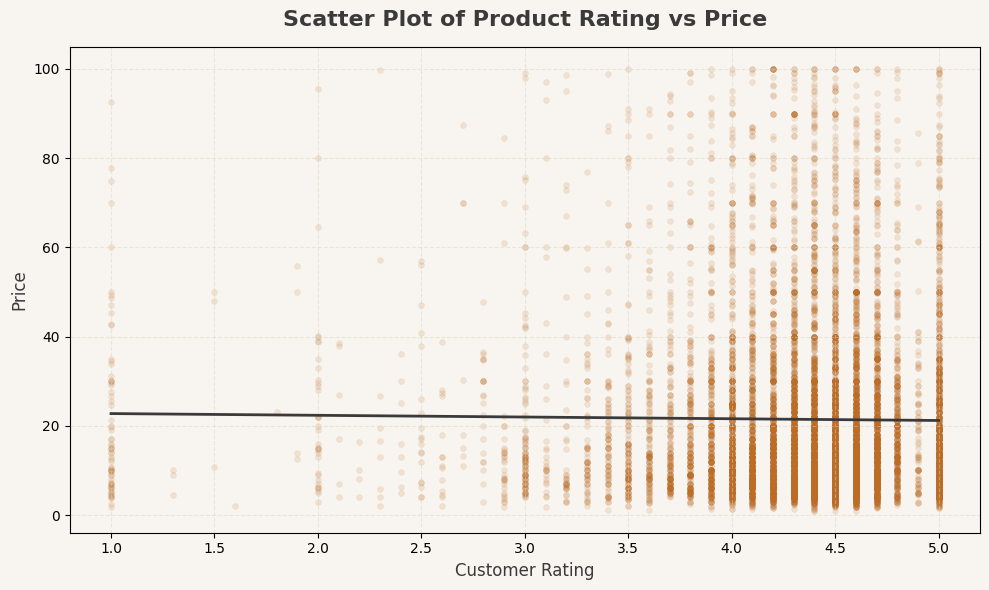

In [49]:
plt.figure(figsize=(10, 6), facecolor=earth_palette["cream"])

ax = sns.scatterplot(data=scatter_data, x="stars", y="price", alpha=0.15, s=18, color=earth_palette["terracotta"], edgecolor=None)

sns.regplot(data=scatter_data, x="stars", y="price", scatter=False, ci=None, color=earth_palette["text"], line_kws={"linewidth": 2})

ax.set_facecolor(earth_palette["cream"])

plt.title("Scatter Plot of Product Rating vs Price", fontsize=16, weight="bold", pad=15, color=earth_palette["text"])
plt.xlabel("Customer Rating", fontsize=12, color=earth_palette["text"])
plt.ylabel("Price", fontsize=12, color=earth_palette["text"])
plt.grid(True, linestyle="--", alpha=0.45, color=earth_palette["grid"])
plt.tight_layout()
plt.show()

The scatter plot shows no clear relationship between product rating and price. Products with similar ratings can have very different prices, and higher-rated products are not consistently more expensive.

Most products are concentrated between 4.0 and 5.0 stars, but prices still vary widely within this rating range. The regression line is almost flat, which supports the previous correlation results: product price and customer rating have a statistically significant but practically negligible relationship.

In [50]:
numeric_df = viz_data.select_dtypes(include=["number"]).copy()

corr_matrix = numeric_df.corr()

corr_matrix

,uid,stars,reviews,price,isBestSeller,boughtInLastMonth
uid,1.000000,-0.007731,0.023758,-0.031281,0.000993,0.018385
stars,-0.007731,1.000000,0.033483,0.006753,0.016698,0.039853
reviews,0.023758,0.033483,1.000000,-0.003158,0.060456,0.097972
price,-0.031281,0.006753,-0.003158,1.000000,-0.021576,-0.073521
isBestSeller,0.000993,0.016698,0.060456,-0.021576,1.000000,0.238960
boughtInLastMonth,0.018385,0.039853,0.097972,-0.073521,0.238960,1.000000


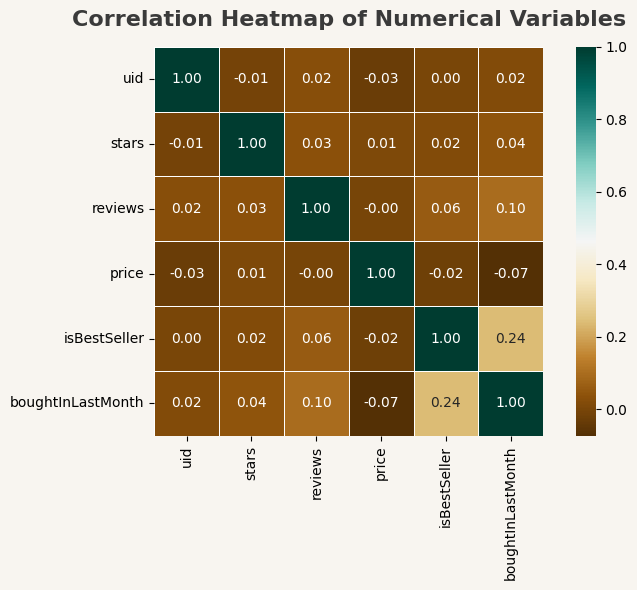

In [51]:
plt.figure(figsize=(8, 6), facecolor=earth_palette["cream"])

ax = sns.heatmap(corr_matrix, annot=True, cmap="BrBG", fmt=".2f", linewidths=0.5, square=True, cbar=True)

ax.set_facecolor(earth_palette["cream"])

plt.title("Correlation Heatmap of Numerical Variables", fontsize=16, weight="bold", pad=15, color=earth_palette["text"])
plt.tight_layout()
plt.show()

The correlation heatmap confirms that price and rating are almost uncorrelated, with a correlation close to 0.01. This means that product price does not meaningfully explain customer rating.

Most numerical variables show very weak correlations with each other. The strongest visible relationship is between `isBestSeller` and `boughtInLastMonth`, with a correlation of 0.24. This suggests a weak positive association between being marked as a best-seller and recent purchase activity.

Overall, the heatmap supports the conclusion that price is not a useful predictor of product rating in this dataset.

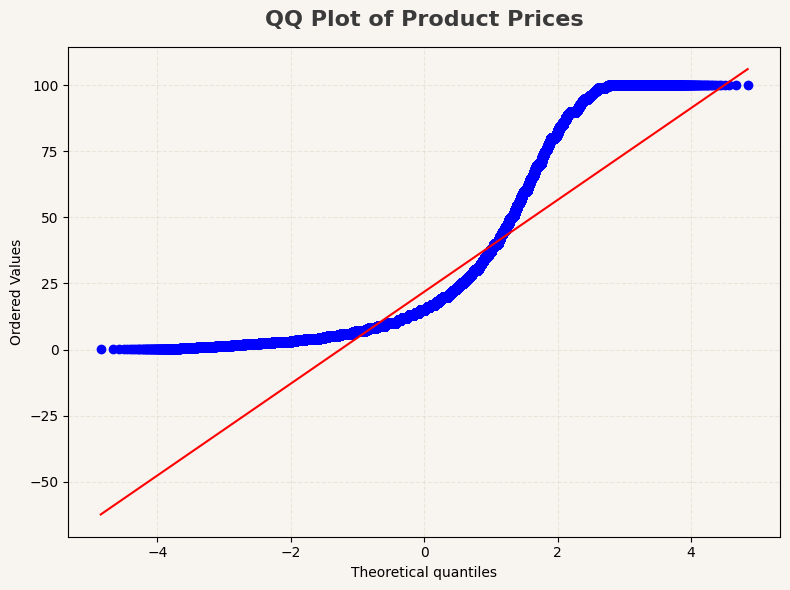

In [56]:
plt.figure(figsize=(8, 6), facecolor=earth_palette["cream"])

ax = plt.gca()
ax.set_facecolor(earth_palette["cream"])

stats.probplot(viz_data["price"], dist="norm", plot=plt)

plt.title("QQ Plot of Product Prices", fontsize=16, weight="bold", pad=15, color=earth_palette["text"])
plt.grid(True, linestyle="--", alpha=0.45, color=earth_palette["grid"])
plt.tight_layout()
plt.show()

The QQ plot of product prices shows a clear deviation from the reference line, indicating that prices do not follow a normal distribution. Even after removing price outliers using the IQR method, the distribution remains skewed and concentrated around lower price values.

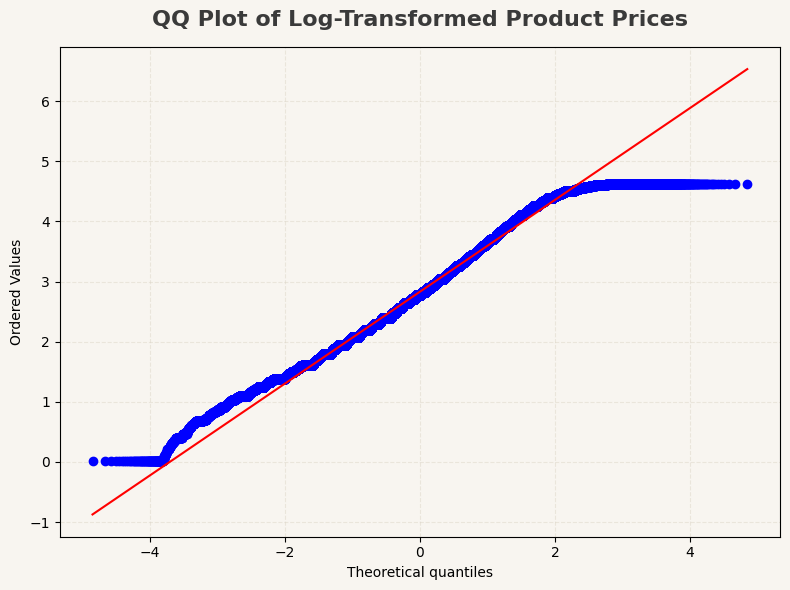

In [57]:
plt.figure(figsize=(8, 6), facecolor=earth_palette["cream"])

ax = plt.gca()
ax.set_facecolor(earth_palette["cream"])

stats.probplot(np.log1p(viz_data["price"]), dist="norm", plot=plt)

plt.title("QQ Plot of Log-Transformed Product Prices", fontsize=16, weight="bold", pad=15, color=earth_palette["text"])
plt.grid(True, linestyle="--", alpha=0.45, color=earth_palette["grid"])
plt.tight_layout()
plt.show()

After applying a log transformation to product prices, the QQ plot shows a much better alignment with the reference line, especially in the central part of the distribution. This suggests that log-transformed prices are closer to a normal distribution than raw prices.

However, the distribution is still not perfectly normal, as deviations remain in both tails. This indicates that the log transformation improves normality but does not fully normalize the price distribution.